In [1]:
import numpy as np
import pandas as pd
import your
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import sys
import matplotlib as mpl
from matplotlib import colors
from scipy.optimize import curve_fit, leastsq
import numpy.ma as ma
import matplotlib.ticker as ticker
from matplotlib.ticker import MaxNLocator

from typing import Union, List

import frb_functions

In [2]:
def gaus(x,a,x0,sigma,d):
    return a*np.exp(-(x-x0)**2/(2*sigma**2))+d

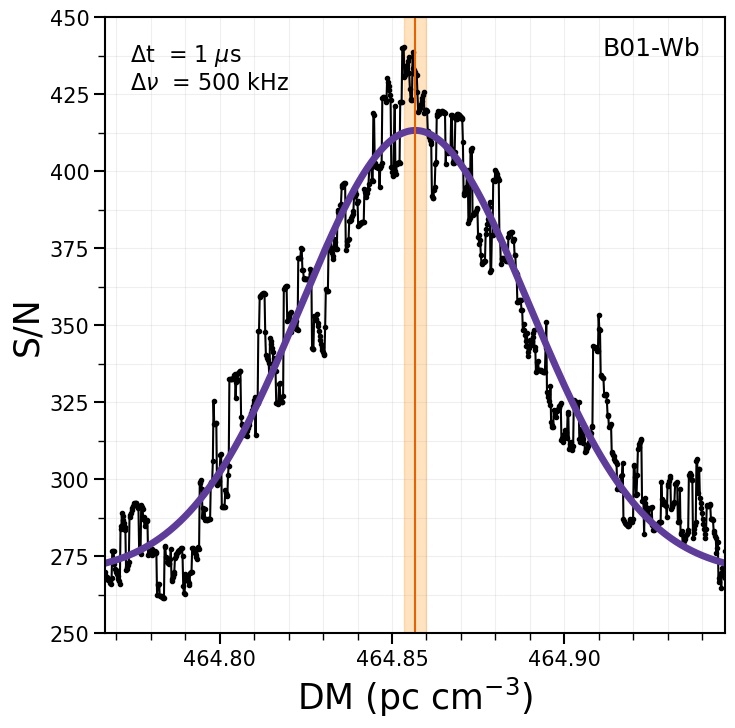

464.857 +- 0.003 pc/cc


In [3]:
def sn_vs_dm_1peak(csv, fsamp, tsamp):

    df = pd.read_csv(csv, sep=",", header=0, index_col=0)
    
    #Filter on the DM grid that has to be fitted, we don't want to take into account a wider dm-range 
    #df_filter = df[(df['DM'] > 219.65) & (df['DM'] < 219.8)] 
    sn_filter = df["sn_peak"].values
    dm_filter = df["DM"].values 
    poptc,pcovc=curve_fit(gaus, dm_filter, sn_filter, p0=[0,464.87,0.1,200], maxfev=10000)
    best_dm = poptc[1]
    sigma_3_err = 3*poptc[2]/np.sqrt(len(dm_filter))
    
    #Retrieving the entire grid space from the df
    sn_range = df["sn_peak"].values 
    dm_range = df["DM"].values 
    
    ##Figure
    fig,ax=plt.subplots(figsize=(8,8))
    
    #Plotting the whole range
    plt.plot(dm_range, sn_range,'.',color='k',ls='-')
    
    #Plotting only the gaussian
    dm_space = np.linspace(dm_filter[0], dm_filter[-1], 10000)
    plt.plot(dm_space,gaus(dm_space,*poptc),color='#5e3c99',lw=5)
    
    plt.axvline(best_dm,color="#e66101")
    plt.axvspan(xmin=best_dm-sigma_3_err, xmax=best_dm+sigma_3_err, ymin=0, ymax=1, color='darkorange', alpha=0.25)
 
    plt.xlabel(r'DM (pc cm$^{-3})$',size=25)
    plt.ylabel('S/N',size=25)
    plt.ylim(250,450)
    dm = poptc[1]
    offset = 0.09
    plt.xlim(dm-offset,dm+offset)

    ax.text(0.96, 0.969, f"B01-Wb", transform=ax.transAxes, fontsize=18, va='top', ha='right')
    
    ax.yaxis.set_major_locator(ticker.MultipleLocator(25))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(12.5))

    ax.xaxis.set_major_locator(ticker.MultipleLocator(0.05))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(0.01))

    for axis in ['top', 'bottom', 'left', 'right']:
        ax.spines[axis].set_linewidth(1.5)
        ax.tick_params(axis='both', which='major', labelsize=15, width=1.5, length=8)
        ax.tick_params(axis='both', which='minor', labelsize=15, width=1, length=5)

    plt.grid(which="both", alpha=0.2)

    ax.text(0.04, 0.96, fr"$\Delta$t  = {(tsamp):.0f} $\mu$s" + "\n" + fr"$\Delta \nu$  = {(fsamp):.0f} kHz " ,\
            transform=ax.transAxes, fontsize=16, va='top', ha='left')

    # plot_name = "NRT_B01_DM_opt"
    # fig.savefig(plot_name + ".pdf", dpi=600, bbox_inches='tight')
    plt.show()
    
    print(f'{np.round(poptc[1],3)} +- {np.round(3*poptc[2]/np.sqrt(len(dm_range)),3)} pc/cc')
    
    return
sn_vs_dm_1peak(csv="p55025_28_1us_1000steps_00002_peak_sn.csv", tsamp=1, fsamp=500)

In [ ]:
sn_vs_dm_1peak(csv="pea")